In [ ]:
# Herramienta de Google Colab para conectar el notebook con Google Drive
from google.colab import drive
# Monta (conecta) Google Drive en este entorno para poder leer y guardar archivos ahí
drive.mount('/content/MyDrive')

Drive already mounted at /content/MyDrive; to attempt to forcibly remount, call drive.mount("/content/MyDrive", force_remount=True).


In [ ]:
import os
# Cambia la carpeta de trabajo actual a la carpeta del proyecto dentro de Drive
os.chdir('/content/MyDrive/MyDrive/Proyecto_glaucoma')

In [ ]:
import os
# OpenCV: librería para leer, procesar y transformar imágenes
import cv2
# NumPy: librería para trabajar con arreglos numéricos (matrices) de forma eficiente
import numpy as np
# Matplotlib: librería para crear gráficos y mostrar imágenes
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, Dense, Dropout,
    BatchNormalization, GlobalAveragePooling2D
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, roc_curve

In [ ]:
# Rutas
base_path = 'data_2000train_200val_240test'

# Carga un arreglo NumPy previamente guardado en disco (archivo .npy)
X_train = np.load(os.path.join(base_path, 'train', 'X_train.npy'))
y_train = np.load(os.path.join(base_path, 'train', 'y_train.npy'))

X_val = np.load(os.path.join(base_path, 'val', 'X_val.npy'))
y_val = np.load(os.path.join(base_path, 'val', 'y_val.npy'))

X_test = np.load(os.path.join(base_path, 'test', 'X_test.npy'))
y_test = np.load(os.path.join(base_path, 'test', 'y_test.npy'))

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_val  :", X_val.shape, "y_val  :", y_val.shape)
print("X_test :", X_test.shape, "y_test :", y_test.shape)

# Cuenta cuántos elementos únicos hay (aquí, cuántas imágenes hay de cada clase)
print("Distribución train:", np.unique(y_train, return_counts=True))
print("Distribución val  :", np.unique(y_val, return_counts=True))
print("Distribución test :", np.unique(y_test, return_counts=True))

X_train: (4000, 220, 220, 3) y_train: (4000,)
X_val  : (400, 220, 220, 3) y_val  : (400,)
X_test : (480, 220, 220, 3) y_test : (480,)
Distribución train: (array([0, 1], dtype=int32), array([2000, 2000]))
Distribución val  : (array([0, 1], dtype=int32), array([200, 200]))
Distribución test : (array([0, 1], dtype=int32), array([240, 240]))


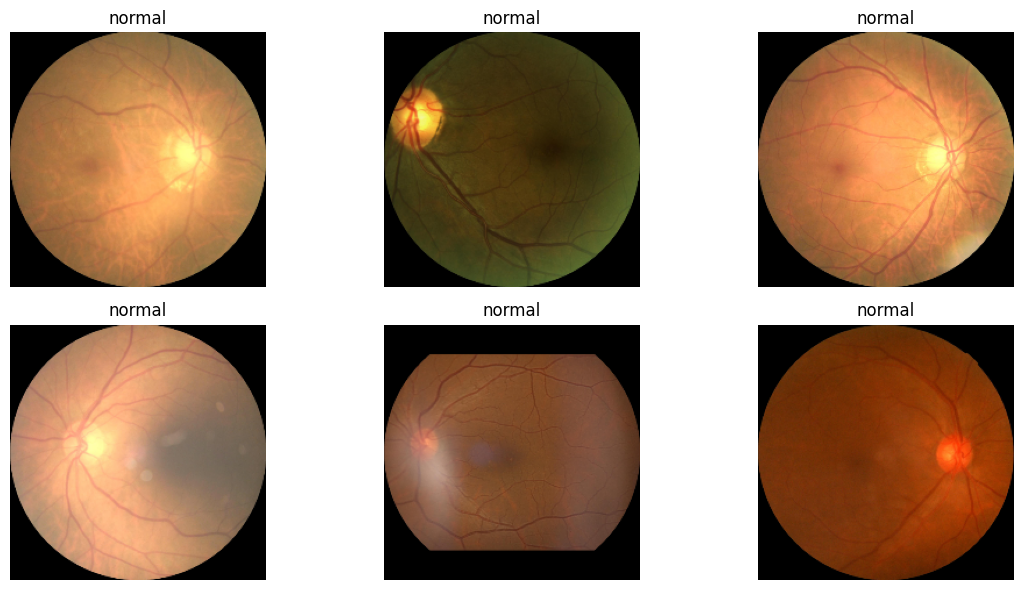

In [ ]:
labels_map = {0: 'normal', 1: 'glaucoma'}

# Crea una nueva figura (lienzo) donde se dibujará el gráfico
plt.figure(figsize=(12, 6))
for i in range(6):
    # Divide la figura en una cuadrícula y selecciona en qué posición dibujar
    plt.subplot(2, 3, i+1)
    # OpenCV lee las imágenes en formato de color BGR; esto las convierte a RGB, que es el formato correcto para mostrarlas con matplotlib
    img_rgb = cv2.cvtColor(X_train[i], cv2.COLOR_BGR2RGB)
    # Muestra una imagen en pantalla
    plt.imshow(img_rgb)
    # Agrega un título al gráfico o imagen mostrada
    plt.title(labels_map[int(y_train[i])])
    # Oculta o ajusta los ejes del gráfico (por estética)
    plt.axis('off')
plt.tight_layout()
# Renderiza (dibuja) el gráfico en pantalla
plt.show()

In [ ]:
X_train = X_train.astype('float32') / 255.0
X_val   = X_val.astype('float32') / 255.0
X_test  = X_test.astype('float32') / 255.0

In [ ]:
# Data augmentation: genera variaciones artificiales de las imágenes (rotaciones, volteos, zoom) para que el modelo generalice mejor y no memorice
train_datagen = ImageDataGenerator(
    rotation_range=3,
    width_shift_range=0.03,
    height_shift_range=0.03,
    zoom_range=0.05,
    brightness_range=(0.95, 1.05),
    horizontal_flip=False,
    vertical_flip=False,
    fill_mode='nearest'
)

# Para validación y prueba no se usa augmentation
val_datagen = ImageDataGenerator()
test_datagen = ImageDataGenerator()

In [ ]:
batch_size = 16

train_generator = train_datagen.flow(
    X_train, y_train,
    batch_size=batch_size,
    shuffle=True
)

val_generator = val_datagen.flow(
    X_val, y_val,
    batch_size=batch_size,
    shuffle=False
)

In [ ]:
# Crear versión espejada
X_train_flip = np.flip(X_train, axis=2)  # eje horizontal

# Concatenar
X_train_aug = np.concatenate([X_train, X_train_flip], axis=0)
y_train_aug = np.concatenate([y_train, y_train], axis=0)

print("Nuevo tamaño:", X_train_aug.shape, y_train_aug.shape)

Nuevo tamaño: (8000, 220, 220, 3) (8000,)


In [ ]:
def modelo_CNN():
    model = Sequential()

    model.add(Input(shape=(220, 220, 3)))

    # Capa convolucional: 'escanea' la imagen buscando patrones visuales como bordes, texturas y formas
    model.add(Conv2D(32, (3, 3), padding='same', activation='relu'))
    # Normaliza las activaciones internas de la red, lo que suele acelerar y estabilizar el entrenamiento
    model.add(BatchNormalization())
    # Reduce el tamaño de la imagen quedándose con la información más relevante (submuestreo)
    model.add(MaxPooling2D((2, 2)))

    model.add(Conv2D(64, (3, 3), padding='same', activation='relu'))
    model.add(BatchNormalization())
    model.add(MaxPooling2D((2, 2)))

    model.add(Conv2D(128, (3, 3), padding='same', activation='relu'))
    model.add(BatchNormalization())
    model.add(MaxPooling2D((2, 2)))

    model.add(GlobalAveragePooling2D())

    # Capa 'densa' o totalmente conectada: cada neurona recibe todas las salidas de la capa anterior
    model.add(Dense(128, activation='relu'))
    # Apaga aleatoriamente un porcentaje de neuronas durante el entrenamiento, para evitar que el modelo memorice en vez de aprender (sobreajuste)
    model.add(Dropout(0.4))

    model.add(Dense(1, activation='sigmoid'))

    # Configura el modelo antes de entrenar: qué función de pérdida usar, qué optimizador, y qué métricas medir
    model.compile(
        optimizer=Adam(learning_rate=1e-4),
        loss='binary_crossentropy',
        metrics=[
            'accuracy',
            tf.keras.metrics.Precision(name='precision'),
            tf.keras.metrics.Recall(name='recall'),
            tf.keras.metrics.AUC(name='auc')
        ]
    )

    return model

model = modelo_CNN()
model.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_21 (Conv2D)              │ (None, 220, 220, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_21          │ (None, 220, 220, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_21 (MaxPooling2D) │ (None, 110, 110, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_22 (Conv2D)              │ (None, 110, 110, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_22          │ (None, 110, 110, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_22 (MaxPooling2D) │ (None, 55, 55, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_23 (Conv2D)              │ (None, 55, 55, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_23          │ (None, 55, 55, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_23 (MaxPooling2D) │ (None, 27, 27, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_7      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,785 (432.75 KB)

 Trainable params: 110,337 (431.00 KB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
callbacks = [
    # Callback que detiene el entrenamiento automáticamente si el modelo deja de mejorar, ahorrando tiempo y evitando sobreajuste
    EarlyStopping(
        monitor='val_loss',
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),
    # Callback que reduce automáticamente la tasa de aprendizaje cuando el modelo deja de progresar
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        verbose=1
    ),
    # Callback que guarda automáticamente la mejor versión del modelo durante el entrenamiento
    ModelCheckpoint(
        'mejor_modelo_conservador.keras',
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    )
]

In [ ]:
# Entrena el modelo: le muestra los datos de entrenamiento repetidamente y ajusta sus pesos internos para reducir el error
history = model.fit(
    X_train_aug, y_train_aug,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=16,
   # callbacks=callbacks,
    verbose=1
)

Epoch 1/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - accuracy: 0.6221 - auc: 0.6833 - loss: 0.6356 - precision: 0.6193 - recall: 0.6340 - val_accuracy: 0.5700 - val_auc: 0.6360 - val_loss: 0.6548 - val_precision: 0.5519 - val_recall: 0.7450
Epoch 2/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.6662 - auc: 0.7377 - loss: 0.5993 - precision: 0.6665 - recall: 0.6655 - val_accuracy: 0.6525 - val_auc: 0.7463 - val_loss: 0.5889 - val_precision: 0.6235 - val_recall: 0.7700
Epoch 3/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.6921 - auc: 0.7675 - loss: 0.5729 - precision: 0.6931 - recall: 0.6895 - val_accuracy: 0.6850 - val_auc: 0.7684 - val_loss: 0.5646 - val_precision: 0.7434 - val_recall: 0.5650
Epoch 4/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.6980 - auc: 0.7811 - loss: 0.5579 - precision: 0.7093 - recall: 0.6710 - val_accuracy: 0.6725 - val_auc: 0.7777 - val_loss: 0.5701 - val_precision: 0.6408 - val_recall: 0.7850
Epoch 5/100
500/500 ━━━━━━

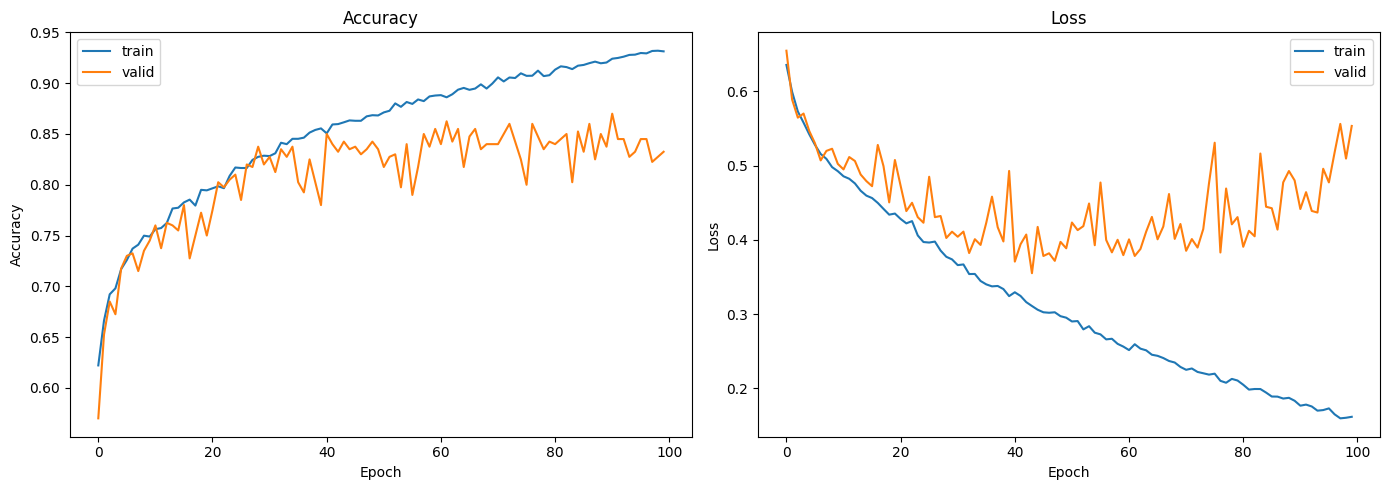

In [ ]:
history_dict = history.history

# Crea una nueva figura (lienzo) donde se dibujará el gráfico
plt.figure(figsize=(14, 5))

# Divide la figura en una cuadrícula y selecciona en qué posición dibujar
plt.subplot(1, 2, 1)
plt.plot(history_dict['accuracy'], label='train')
plt.plot(history_dict['val_accuracy'], label='valid')
# Agrega un título al gráfico o imagen mostrada
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_dict['loss'], label='train')
plt.plot(history_dict['val_loss'], label='valid')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
# Renderiza (dibuja) el gráfico en pantalla
plt.show()

In [ ]:
# Usa el modelo entrenado para generar predicciones sobre nuevas imágenes
y_pred_prob = model.predict(X_test).flatten()

print("Primeras 10 probabilidades:")
print(y_pred_prob[:10])
print("min:", y_pred_prob.min())
print("max:", y_pred_prob.max())
print("mean:", y_pred_prob.mean())

threshold = 0.5
y_pred = (y_pred_prob > threshold).astype(int)

# Cuenta cuántos elementos únicos hay (aquí, cuántas imágenes hay de cada clase)
print("Distribución de predicciones:", np.unique(y_pred, return_counts=True))

from sklearn.metrics import confusion_matrix
# Calcula la matriz de confusión: compara las predicciones del modelo contra las etiquetas reales
cm = confusion_matrix(y_test, y_pred)
print(cm)

15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step
Primeras 10 probabilidades:
[0.15031917 0.34764963 0.872285   0.83044285 0.01570561 0.14486778
 0.02058888 0.00208612 0.01638431 0.14607769]
min: 0.00043216013
max: 0.9999995
mean: 0.36193976
Distribución de predicciones: (array([0, 1]), array([333, 147]))
[[223  17]
 [110 130]]


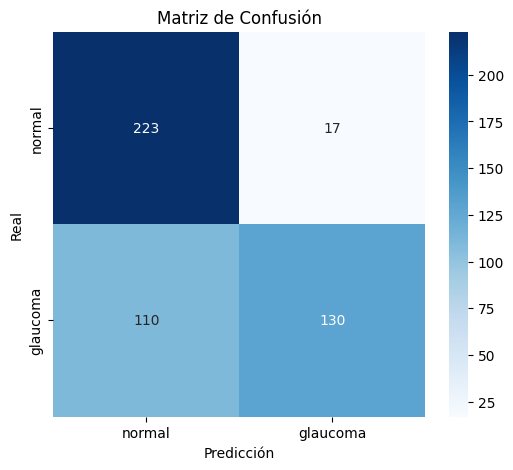

In [ ]:
import seaborn as sns
# Matplotlib: librería para crear gráficos y mostrar imágenes
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Calcula la matriz de confusión: compara las predicciones del modelo contra las etiquetas reales
cm = confusion_matrix(y_test, y_pred)

labels = ['normal', 'glaucoma']

# Crea una nueva figura (lienzo) donde se dibujará el gráfico
plt.figure(figsize=(6,5))
# Dibuja la matriz de confusión como un mapa de calor, más fácil de leer visualmente
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel('Predicción')
plt.ylabel('Real')
# Agrega un título al gráfico o imagen mostrada
plt.title('Matriz de Confusión')
# Renderiza (dibuja) el gráfico en pantalla
plt.show()

In [ ]:
# Guarda el modelo entrenado (su arquitectura y pesos aprendidos) en un archivo .keras para reutilizarlo sin re-entrenar
model.save('modelo_CNN_4.keras')